# Coğrafi Görselleştirme: folium

Bu derste veriyi gerçek dünyanın üzerine koyuyoruz: haritalar. 2. dersten beri şehir adlarını eksenlerde taşıdık; bugün aynı şehirleri coğrafi konumlarıyla göreceğiz. folium kütüphanesiyle interaktif OpenStreetMap haritaları üretecek, şehirleri işaretleyeceğiz ve büyüklüğü daire boyutuyla kodlayacağız.

> **Önemli:** Bu dersteki haritalar, defteri kendi ortamında (ya da Colab'da) çalıştırdığında canlı görünür: sürüklenir, yakınlaşılır, işaretlere tıklanır. GitHub'ın defter önizlemesi JavaScript çalıştırmadığı için her haritanın kod hücresinin çıktısında, o haritanın **statik bir kopyası** (PNG) yer alıyor: GitHub'da görünen budur, etkileşim için defteri kendi ortamında çalıştır.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- folium ile Türkiye odaklı temel bir harita oluşturmak
- Enlem-boylam koordinatlarıyla işaret (marker) yerleştirmek
- Değere göre boyutlanan daire işaretler (`CircleMarker`) çizmek
- İşaretlere bilgi kutucuğu (popup) ve ipucu (tooltip) eklemek
- Coğrafi görselleştirmenin ne zaman uygun olduğunu, ne zaman grafik tercih edileceğini karar vermek

Bu ders, kursun 9. öğrenme çıktısının ikinci yarısını karşılıyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

Kahve zincirimiz büyüdü: 2. dersteki üç şehirden on şehre çıktık. "Hangi şehirde kaç müşteri var?" sorusu bir çubuk grafikle yanıtlanır; ama "şubeler coğrafi olarak nasıl dağılmış, batı mı doğu mu ağırlıklı, nerede boşluk var?" sorusunun cevabı yalnız haritada görünür. Coğrafi görselleştirme, **konumun kendisinin bilgi olduğu** durumlarda kullanılır.

Dikkat: harita her zaman daha iyi değildir. Değerleri tam karşılaştırmak çubuk grafikte daha kolaydır (uzunluk algısı); harita konum örüntüsünü taşır, kesin karşılaştırmayı değil. Bu dersin sonunda hangi sorunun hangi aracı istediğini bileceksin.

## 🔗 Ön Bilgi

- [Etkileşimli Grafikler: plotly](12-Interactive-Plots.ipynb): etkileşimli çıktı ve ortam farkları konusu (renderer, GitHub sınırlaması) orada işlendi.
- [pandas DataFrame](05-Pandas-Dataframe.ipynb): şube verisini tablo olarak hazırlayacağız.
- [Grafik Türleri ve Doğru Seçim](02-Chart-Types.ipynb): haritanın "coğrafi" soru türü.

## 🔍 Birlikte Keşfedelim

folium kurulu değilse terminalden `pip install folium` ile kur. Şimdi ilk haritamız: Türkiye'nin ortasına odaklanmış boş bir harita. Çalıştırmadan önce tahmin et: haritayı Türkiye'ye odaklamak için kodda hangi bilgi gerekir?

**Tahminin:** ...

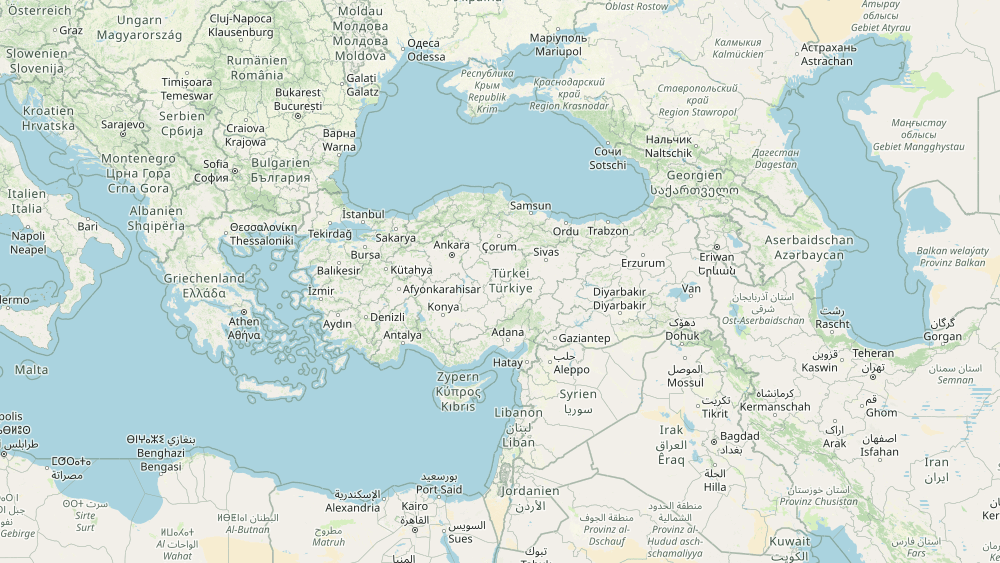

In [1]:
import folium
import pandas as pd

harita = folium.Map(location=[39.0, 35.0], zoom_start=5)
harita

**Gözlem:** `location=[39.0, 35.0]` haritanın merkezini Türkiye'nin yaklaşık ortasına koydu; `zoom_start=5` başlangıç yakınlaşmasını belirledi. Liste sırası önemlidir: **önce enlem (kuzey-güney), sonra boylam (doğu-batı)**. Yaygın hata sırayı ters koymaktır — o zaman harita bambaşka bir yere bakar.

Haritayı kendi ortamında açtıysan sürükle ve yakınlaş: altta yatan harita karoları (tiles) OpenStreetMap'ten gelir, yani **internet gerekir**.


## 📖 Kavramlar

**Enlem ve boylam:** Dünya üzerindeki her noktanın adresi. Enlem kuzey-güney (Türkiye yaklaşık 36-42), boylam doğu-batı (Türkiye yaklaşık 26-45). folium'da `[enlem, boylam]` sırasıyla verilir.

**Tiles (harita karoları):** Haritanın görsel katmanı. Varsayılan `OpenStreetMap` ayrıntılıdır; sade (açık gri) karolar veri üzerine çizilen işaretleri öne çıkarır. Bu derste anahtar gerektirmeyen Esri'nin açık gri karo hizmetini (`World_Light_Gray_Base`) kullanıyoruz; bazı karo hizmetleri (ör. CartoDB) artık API anahtarı istediği için.

**Marker ve CircleMarker:** `Marker` klasik iğne işareti; `CircleMarker` yarıçapı kontrol edilebilen daire. Değer büyüklüğünü göstermek istediğinde daire kullanırsın (1. dersin alan-algısı uyarısıyla: daire boyutu büyürken algı doğrusal büyümez; yorumda buna dikkat et).

**Popup ve tooltip:** Popup, işarete tıklayınca açılan kutu; tooltip, üzerine gelince beliren kısa etiket.

**Nokta haritası mı choropleth mi:** Bu derste nokta/daire haritaları çiziyoruz. Bölge bazlı renklendirme (choropleth) haritası, her ilin sınırlarını taşıyan GeoJSON dosyası gerektirir; kavramı bilmek yeterli, uygulaması bu dersin kapsamında değil.

## 🛠️ Uygulama

### 1) Şube verisi

Zincirimizin on şehri, koordinatları ve müşteri sayıları (bin kişi):

In [2]:
subeler = pd.DataFrame({
    "sehir": ["İstanbul", "Ankara", "İzmir", "Bursa", "Antalya",
              "Adana", "Konya", "Trabzon", "Diyarbakır", "Erzurum"],
    "enlem": [41.01, 39.93, 38.42, 40.19, 36.90,
              37.00, 37.87, 41.00, 37.91, 39.90],
    "boylam": [28.98, 32.86, 27.14, 29.06, 30.70,
               35.32, 32.49, 39.72, 40.24, 41.27],
    "musteri_bin": [820, 540, 460, 310, 290, 250, 220, 150, 120, 90],
})

subeler

,sehir,enlem,boylam,musteri_bin
0,İstanbul,41.01,28.98,820
1,Ankara,39.93,32.86,540
2,İzmir,38.42,27.14,460
3,Bursa,40.19,29.06,310
4,Antalya,36.90,30.70,290
5,Adana,37.00,35.32,250
6,Konya,37.87,32.49,220
7,Trabzon,41.00,39.72,150
8,Diyarbakır,37.91,40.24,120
9,Erzurum,39.90,41.27,90


### 2) İşaretli harita

Her şubeyi klasik iğne işaretiyle, tıklanınca müşteri sayısını gösteren popup'la yerleştirelim:

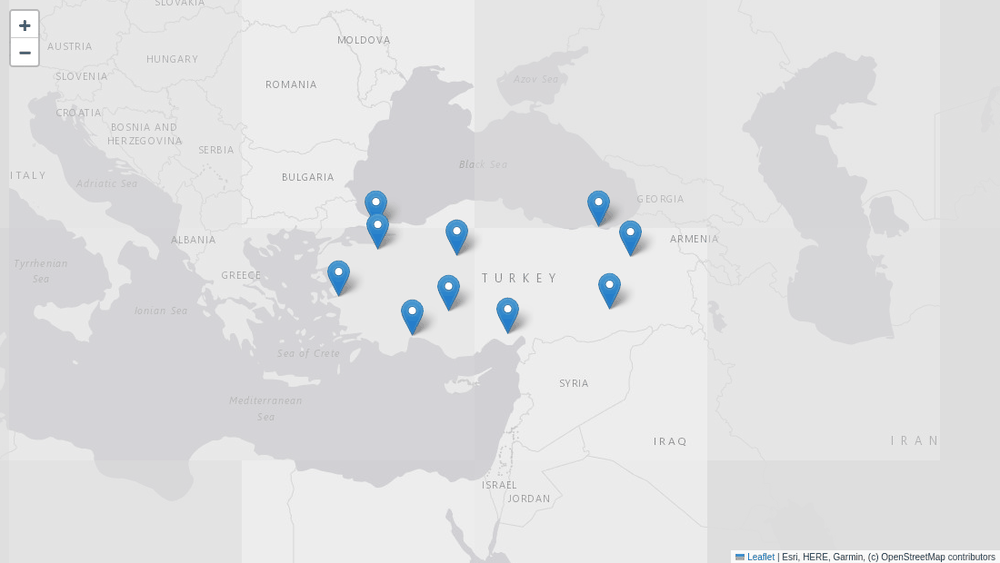

In [3]:
# Anahtar gerektirmeyen sade (açık gri) karo hizmeti: Esri
sade_karo = ("https://server.arcgisonline.com/ArcGIS/rest/services/"
             "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}")
kaynak = "Esri, HERE, Garmin, (c) OpenStreetMap contributors"

harita = folium.Map(location=[39.0, 35.0], zoom_start=5,
                    tiles=sade_karo, attr=kaynak)

for _, sube in subeler.iterrows():
    folium.Marker(
        location=[sube["enlem"], sube["boylam"]],
        popup=f"{sube['sehir']}: {sube['musteri_bin']} bin müşteri",
        tooltip=sube["sehir"],
    ).add_to(harita)

harita

Döngü tablosu satır satır dolaşıyor (4. dersteki döngü kavramı), her satır için bir işaret yaratıp haritaya ekliyor. `tooltip` üzerine gelince şehir adını, `popup` tıklayınca detayı gösterir. `tiles=sade_karo` ve `attr=kaynak` parametreleri ise haritaya kendi karo seçimimizi ve kaynak bilgisini (haritanın kime ait olduğunu) taşır.


### 3) Değere göre boyutlanan daireler

Müşteri sayısını daire boyutuna çevirelim; harita artık yalnız "nerede"yi değil "ne kadar"ı da taşıyacak:

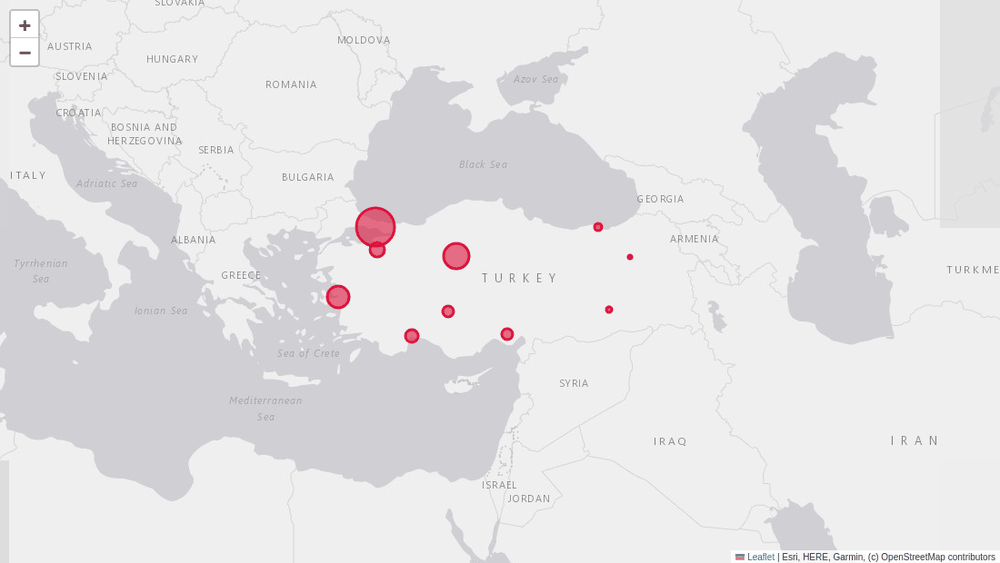

In [4]:
harita2 = folium.Map(location=[39.0, 35.0], zoom_start=5,
                      tiles=sade_karo, attr=kaynak)

for _, sube in subeler.iterrows():
    folium.CircleMarker(
        location=[sube["enlem"], sube["boylam"]],
        radius=sube["musteri_bin"] / 40,          # müşteri sayısına göre boyut
        popup=f"{sube['sehir']}: {sube['musteri_bin']} bin müşteri",
        tooltip=sube["sehir"],
        color="crimson",
        fill=True,
        fill_opacity=0.6,
    ).add_to(harita2)

harita2

**Gözlem:** Batı yakası (İstanbul-Bursa-İzmir üçgeni) kalın dairelerle dolu; doğuya gidildikçe daireler küçülüyor. Bu coğrafi örüntü, çubuk grafikteki sıralamada aynı bilgiyi taşır ama **konum bağlamıyla** taşır: boşlukların nerede olduğu ilk bakışta görülür. `radius`'u `musteri_bin / 40` oranıyla ölçekledik — bölen sayı, dairelerin haritaya göre ne kadar büyüyeceğini ayarlayan tasarım kararıdır.


### 4) Haritayı kaydetmek

plotly'deki `write_html` gibi, folium haritası da bağımsız bir HTML dosyası olur:

In [5]:
harita2.save("sube-haritasi.html")
print("sube-haritasi.html kaydedildi.")

sube-haritasi.html kaydedildi.


Dosya defterin yanına yazıldı; tarayıcıda açılınca tüm etkileşimleriyle çalışır.

### 5) Kodu tamamla (TODO)

In [6]:
# TODO: Doğduğun ya da en çok sevdiğin şehri haritaya ekle:
# 1) koordinatlarını (enlem, boylam) bul,
# 2) subeler tablosuna yeni satır olarak ekle (müşteri sayısını sen belirle),
# 3) daireli haritayı (harita2) yeniden üret.

# Not: Koordinatları internette "şehir adı enlem boylam" aramasıyla bulabilirsin.

print("Kontrol: tabloda", len(subeler), "şube var.")

Kontrol: tabloda 10 şube var.


Çözüm "Cevaplar" bölümünde.

## 🧪 Deneyelim ve Gözlemleyelim

**Deney 1:** Haritalardan birinde `tiles=sade_karo, attr=kaynak` parametrelerini sil (harita varsayılan OpenStreetMap karosuna döner) ve yeniden üret. Sade karo ile ayrıntılı karo arasındaki fark işaretlerin görünürlüğünü nasıl etkiliyor? Kararını 1. dersin "basitlik" ilkesiyle bağla.

**Deney 2:** Daire boyutundaki bölen sayıyla oyna: `musteri_bin / 40` yerine `/ 80` ve `/ 20` dene. Ne zaman daireler birbirine binmeye başlıyor, ne zaman kayboluyor? Ölçekleme neden tasarım kararıdır?

**Deney 3:** `zoom_start=5` yerine `6` ve `4` dene. Haritanın ilk izlenimi nasıl değişiyor? Okuyucuya "tam Türkiye'yi mi, bir bölgeyi mi" göstermek istersin?

## 🧯 Bir Şeyler Ters Giderse

| Belirti | Olası neden | Çözüm |
|---|---|---|
| Harita boş/gri görünüyor | Karolar internetten yüklenemiyor | İnternet bağlantısını kontrol et; karolar OpenStreetMap sunucularından gelir |
| Harita bambaşka bir yere bakıyor | Enlem-boylam sırası ters | Sıra `[enlem, boylam]`; Türkiye için enlem ~36-42, boylam ~26-45 |
| `ModuleNotFoundError: No module named 'folium'` | folium kurulu değil | `pip install folium` |
| İşaretler haritada görünmüyor | `add_to(harita)` unutulmuş ya da döngü yanlış tabloda | Her işaretin `.add_to(...)` ile haritaya eklendiğini kontrol et |
| GitHub'da harita görünmüyor | JavaScript çıktısı; beklenen davranış | Normaldir: GitHub güvenlik nedeniyle JavaScript çalıştırmaz. Defterdeki harita hücrelerinin çıktısında statik PNG kopyası vardır; canlı harita için defteri kendi ortamında çalıştır |

> **İpucu:** Koordinat doğrulama hilesi: enlem değerleri Türkiye için mutlaka 36-42 arasında, boylamlar 26-45 arasında olmalı. Tablonda bu aralıkların dışında değer varsa ya sıra ters ya da yazım hatası vardır.

## 🏋️ Kendin Dene

1. **Nüfus haritası:** Türkiye'nin en kalabalık on ilini nüfus verileriyle (internetten güncel değerlere bakabilirsin) yeni bir tabloya yaz ve daire boyutlu haritasını üret. Müşteri haritasıyla örüntü benziyor mu? Neden?
2. **Karşılaştırma kararı:** Aynı müşteri verisiyle (a) yatay çubuk grafik, (b) daireli harita üret. "Hangi şehir lider?" sorusu hangisinde daha hızlı yanıtlanıyor, "boşluklar nerede?" sorusu hangisinde? Gözlemini üç-dört cümleyle yaz.
3. **Tooltip turu:** Dairelerde `tooltip`'i şehir adı + müşteri sayısı bileşimine çevir (ör. `"İstanbul — 820 bin"`). Üzerine gelerek değer okumak, tıklamaktan ne zaman daha pratik?


## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. Bir sorunun cevabı için harita mı çubuk grafik mi seçersin: "Şube sayısı en çok olan üç şehir hangileri?" ile "Doğu Anadolu'da neden şube yok?" sorularını ayrı ayrı değerlendir.
2. folium'da `location=[41.01, 28.98]` bilgisinde sayılar sırasıyla neyi ifade eder? Sıra ters verilirse ne olur?
3. `Marker` yerine `CircleMarker` kullanmak hangi ek bilgiyi taşımanı sağlar? Bu tercih 1. dersin hangi algı uyarısıyla ilişkilidir?
4. Popup ile tooltip arasındaki fark nedir; hangisi hangi kullanıcı hareketine yanıt verir?
5. Bu dersteki haritalar GitHub defter önizlemesinde neden görünmüyor? Çözüm olarak ne yapıldı?
6. Tiles seçimi (ayrıntılı OpenStreetMap vs sade açık gri karo) hangi tasarım ilkesiyle doğrudan ilişkilidir?

## 🚀 Bağımsız Çalışma

- **Choropleth keşfi:** Bölge bazlı renkli haritalar (choropleth) nasıl yapılır? folium belgelerindeki choropleth örneğini incele: ne tür ek dosya (GeoJSON) gerektiriyor, renk ölçeği nasıl belirleniyor? Deneylemek istersen Türkiye il sınırları GeoJSON'unu açık veri portallarında arayabilirsin.
- **Kendi haritan:** Yaşadığın mahalle ölçeğinde bir nokta haritası yap: sevdiğin 8-10 mekânın (kahvehane, kütüphane, park...) koordinatlarını haritaya işaretleyip tooltip'lerle adlandır.

## 📚 Daha Fazlasını Öğrenmek

- folium belgeleri ve örnekler: https://python-visualization.github.io/folium/
- OpenStreetMap: https://www.openstreetmap.org

İngilizcedir; kodlar doğrudan çalıştırılabilir.

## ✅ Kısa Özet

- Coğrafi görselleştirme, konumun bilgi olduğu sorularda kullanılır; kesin karşılaştırma gerektiren sorularda grafik daha iyidir.
- folium haritası `folium.Map(location=[enlem, boylam], zoom_start=...)` ile kurulur; sıra önce enlem sonra boylamdır.
- `Marker` konumu, `CircleMarker` konum + büyüklük taşır; boyut ölçekleme (`radius`) tasarım kararıdır.
- `tooltip` üzerine gelince, `popup` tıklayınca açılır.
- Harita karoları internetten gelir; çıktı HTML+JavaScript'tir: Jupyter'de canlı, GitHub'da yalnız statik PNG kopyası görünür (her harita hücresinin çıktısına gömülüdür).
- `harita.save("...html")` haritayı bağımsız etkileşimli dosyaya yazar.

Sıradaki derste üç boyutlu grafiklere çıkıyoruz: yüzey ve 3B dağılım grafikleri, hem matplotlib hem plotly ile.

---

[← Önceki ders: Etkileşimli Grafikler: plotly](12-Interactive-Plots.ipynb) · [Sıradaki ders: Üç Boyutlu Grafikler →](14-Three-Dimensional-Plots.ipynb)

## Cevaplar

### Kendin Dene 5: yeni şehir (TODO çözümü)

```python
yeni = pd.DataFrame({
    "sehir": ["Samsun"],
    "enlem": [41.29],
    "boylam": [36.33],
    "musteri_bin": [130],
})
subeler = pd.concat([subeler, yeni], ignore_index=True)

harita3 = folium.Map(location=[39.0, 35.0], zoom_start=5,
                    tiles=sade_karo, attr=kaynak)
for _, sube in subeler.iterrows():
    folium.CircleMarker(
        location=[sube["enlem"], sube["boylam"]],
        radius=sube["musteri_bin"] / 40,
        popup=f"{sube['sehir']}: {sube['musteri_bin']} bin müşteri",
        tooltip=sube["sehir"],
        color="crimson", fill=True, fill_opacity=0.6,
    ).add_to(harita3)
harita3
```

(Kendi şehrinin koordinatları ve müşteri sayısı farklı olabilir; önemli olan tabloya satır ekleyip haritayı yeniden üretmek.)

### Kontrol Et 1

"En çok şubeli üç şehir" → çubuk grafik: uzunluk karşılaştırması kesin sıralama verir, haritada daireler birbirine uzak olduğu için boyut karşılaştırması zayıf kalır. "Doğu Anadolu'da neden şube yok?" → harita: boşluk ve örüntü ancak coğrafi bağlamda görünür; çubuk grafik sıralamada boşluk "olmayan kategori" olarak görünmez.

### Kontrol Et 2

41.01 enlem (kuzey-güny konumu), 28.98 boylam (doğu-batı konumu). Sıra ters verilirse harita 41. boylam, 29. enleme (okyanus açıkları) bakar; Türkiye görünmez.

### Kontrol Et 3

Büyüklük (değer) bilgisini. 1. dersteki uyarı: insan gözü alanları uzunluklar kadar doğru karşılaştıramaz; daireler büyüdükçe alan karesel artar ve küçük farklar abartılı algılanabilir. Bu yüzden popup/tooltip ile tam değer de sunmak gerekir.

### Kontrol Et 4

Tooltip, işaretin üzerine gelince (hover) görünen kısa etikettir; popup, tıklanınca açılan detay kutusudur. Hızlı tarama tooltip, kalıcı inceleme popup ister.

### Kontrol Et 5

Çıktı HTML+JavaScript'tir; GitHub defter önizlemesi güvenlik nedeniyle JavaScript çalıştırmaz. Çözüm: her haritanın kod hücresinin çıktısında, o haritanın statik PNG kopyası gömülü olarak durur; haritayı canlı görmek isteyen defteri kendi ortamında çalıştırır.

### Kontrol Et 6

Basitlik. Ayrıntılı karolar veri işaretleriyle yarışır ve dikkati böler; sade açık gri karolar mesajı taşıyan öğeleri öne çıkarır.

### İpuçları

**Kendin Dene:** 1. görevde nüfus verilerini yazarken kaynak notu düşün (6. dersin karar günlüğü alışkanlığı). 2. görevde ölçüt: uzunluk karşılaştırması (çubuk) kesin sıralama verir; harita coğrafi örüntü ve boşlukları verir.
